# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** _Moulya HR__ &nbsp;&nbsp; **Roll No.:** __1RUA25CSE0274__ &nbsp;&nbsp; **Date:** __11/11/2026__

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

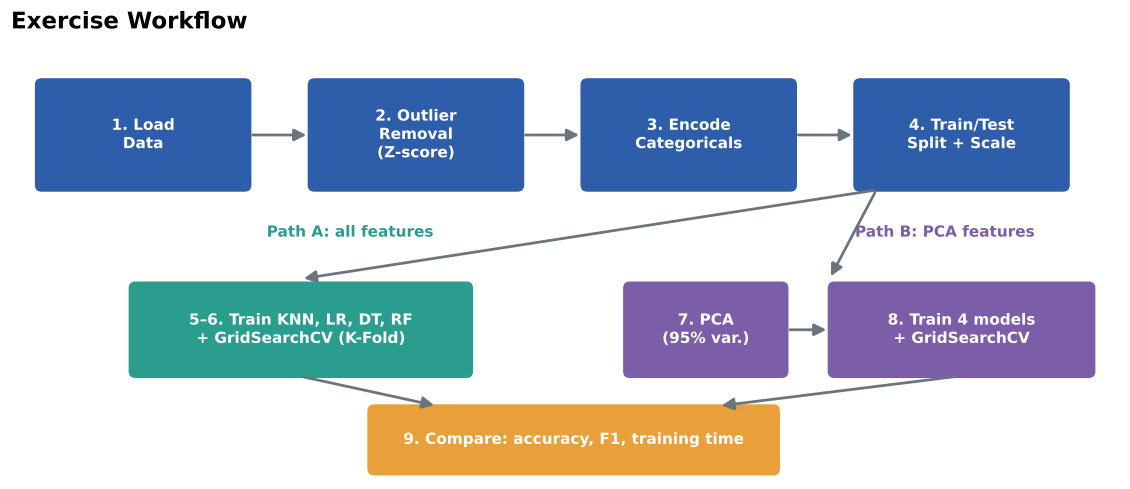

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy.stats import zscore

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.decomposition import PCA

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
sns.set_theme(style="whitegrid")

---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [2]:
from pathlib import Path

data_path = Path("heart.csv")
if not data_path.exists():
    data_path = Path("Exercise") / "heart.csv"

df = pd.read_csv(data_path)
print(f"Loaded dataset from: {data_path}")
display(df.head())

Loaded dataset from: heart.csv


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0000,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0000,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0000,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5000,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0000,Up,0


### 1.2 Dimensions, column names and data types

In [3]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))

Shape: (918, 12)

Column names:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Data types:


,dtype
Age,int64
Sex,str
ChestPainType,str
RestingBP,int64
Cholesterol,int64
FastingBS,int64
RestingECG,str
MaxHR,int64
ExerciseAngina,str
Oldpeak,float64


### 1.3 Check for missing values

In [4]:
missing_values = df.isnull().sum()
print("Missing values in each column:")
display(missing_values.to_frame("missing_count"))

print("\nTotal missing values:", int(missing_values.sum()))

Missing values in each column:


,missing_count
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0



Total missing values: 0


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

In [5]:
class_counts = df["HeartDisease"].value_counts().sort_index()
class_percent = df["HeartDisease"].value_counts(normalize=True).sort_index() * 100

display(pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percent.round(2)
}).rename(index={0: "No heart disease (0)", 1: "Heart disease (1)"}))

print("\nDescriptive statistics:")
display(df.describe())

,Count,Percentage
HeartDisease,,
No heart disease (0),410,44.6600
Heart disease (1),508,55.3400



Descriptive statistics:


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.0000,918.0000,918.0000,918.0000,918.0000,918.0000,918.0000
mean,53.5109,132.3965,198.7996,0.2331,136.8094,0.8874,0.5534
std,9.4326,18.5142,109.3841,0.4230,25.4603,1.0666,0.4974
min,28.0000,0.0000,0.0000,0.0000,60.0000,-2.6000,0.0000
25%,47.0000,120.0000,173.2500,0.0000,120.0000,0.0000,0.0000
50%,54.0000,130.0000,223.0000,0.0000,138.0000,0.6000,1.0000
75%,60.0000,140.0000,267.0000,0.0000,156.0000,1.5000,1.0000
max,77.0000,200.0000,603.0000,1.0000,202.0000,6.2000,1.0000


**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

**Answer:** The dataset contains **918 rows and 12 columns**. The text-based categorical columns are `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, and `ST_Slope`. There are no explicit missing (`NaN`) values. However, `RestingBP` contains **1 zero** and `Cholesterol` contains **172 zeros**, which are medically implausible and can be treated as hidden missing/invalid values. The class distribution is 508 patients with heart disease and 410 without it.

---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.

![zscore](attachment:zscore.png)

**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

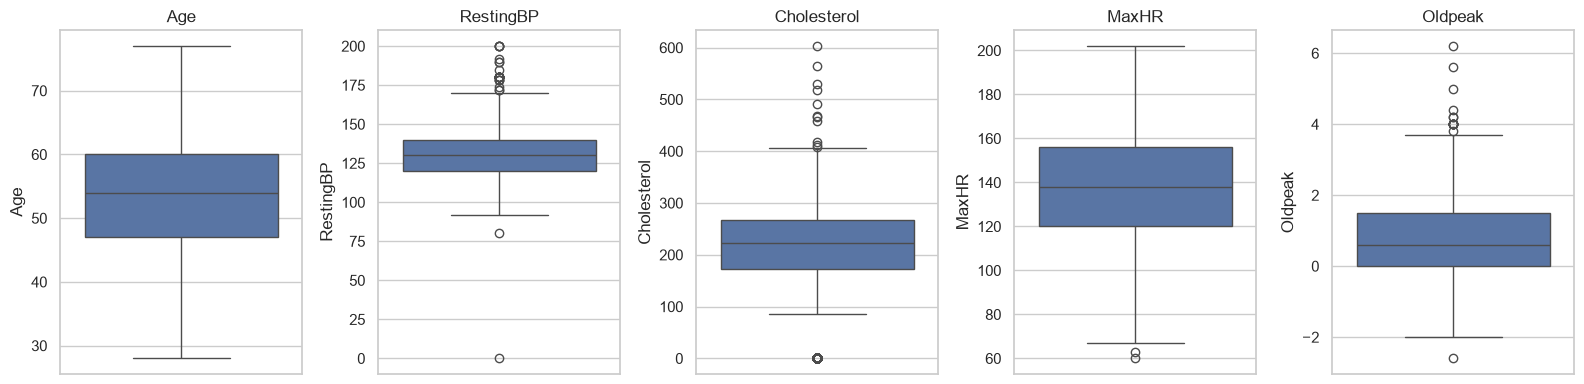

In [6]:
numeric_outlier_features = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

fig, axes = plt.subplots(1, len(numeric_outlier_features), figsize=(16, 4))
for ax, col in zip(axes, numeric_outlier_features):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 2.2 Calculate Z-scores for the numerical features

In [7]:
z_scores = pd.DataFrame(
    zscore(df[numeric_outlier_features], nan_policy="omit"),
    columns=numeric_outlier_features,
    index=df.index
)

display(z_scores.head())
print("Absolute Z-score > 3 is treated as an outlier.")

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,-1.4331,0.4109,0.8251,1.3829,-0.8324
1,-0.4785,1.4918,-0.1720,0.7542,0.1057
2,-1.7514,-0.1295,0.7702,-1.5251,-0.8324
3,-0.5846,0.3028,0.1390,-1.1322,0.5747
4,0.0519,0.9513,-0.0348,-0.5820,-0.8324


Absolute Z-score > 3 is treated as an outlier.


### 2.3 Identify and count the outlier records

In [8]:
outlier_mask = z_scores.abs().gt(3).any(axis=1)
outlier_count = int(outlier_mask.sum())

feature_outlier_counts = z_scores.abs().gt(3).sum().sort_values(ascending=False)

print("Number of records containing at least one outlier:", outlier_count)
print("\nOutlier count by feature:")
display(feature_outlier_counts.to_frame("outlier_count"))

Number of records containing at least one outlier: 19

Outlier count by feature:


,outlier_count
RestingBP,8
Oldpeak,7
Cholesterol,3
MaxHR,1
Age,0


### 2.4 Remove the outliers and display the new shape

In [9]:
shape_before_outlier_removal = df.shape
df_clean = df.loc[~outlier_mask].reset_index(drop=True)
shape_after_outlier_removal = df_clean.shape

print("Shape before outlier removal:", shape_before_outlier_removal)
print("Shape after outlier removal :", shape_after_outlier_removal)
print("Records removed:", shape_before_outlier_removal[0] - shape_after_outlier_removal[0])

df = df_clean.copy()

Shape before outlier removal: (918, 12)
Shape after outlier removal : (899, 12)
Records removed: 19


**Q2.** How many records were removed? Which feature contributed the most outliers?

**Answer:** Using the specified Z-score rule (`|z| > 3`) on `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, and `Oldpeak`, **19 records were removed**. `RestingBP` contributed the most detected outliers, with **8 records**, followed by `Oldpeak` with 7, `Cholesterol` with 3, and `MaxHR` with 1. `Age` had no Z-score outliers.

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.

![encoding](attachment:encoding.png)

| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [10]:
categorical_features = df.select_dtypes(include="object").columns.tolist()

print("Categorical features:", categorical_features)
for col in categorical_features:
    print(f"\n{col} unique values:")
    print(sorted(df[col].dropna().unique().tolist()))

Categorical features: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

Sex unique values:
['F', 'M']

ChestPainType unique values:
['ASY', 'ATA', 'NAP', 'TA']

RestingECG unique values:
['LVH', 'Normal', 'ST']

ExerciseAngina unique values:
['N', 'Y']

ST_Slope unique values:
['Down', 'Flat', 'Up']


C:\Users\HP\AppData\Local\Temp\ipykernel_35768\4045398741.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include="object").columns.tolist()


### 3.2 Apply Label Encoding

In [11]:
binary_categorical = ["Sex", "ExerciseAngina"]

label_maps = {
    "Sex": {"F": 0, "M": 1},
    "ExerciseAngina": {"N": 0, "Y": 1}
}

for col in binary_categorical:
    df[col] = df[col].map(label_maps[col])

print("Binary categorical features after label encoding:")
display(df[binary_categorical].head())

Binary categorical features after label encoding:


,Sex,ExerciseAngina
0,1,0
1,0,0
2,1,0
3,0,1
4,1,0


### 3.3 Apply One-Hot Encoding

In [12]:
nominal_categorical = ["ChestPainType", "RestingECG", "ST_Slope"]

df = pd.get_dummies(
    df,
    columns=nominal_categorical,
    drop_first=True,
    dtype=int
)

print("One-hot encoding applied with drop_first=True.")
print("New shape:", df.shape)

One-hot encoding applied with drop_first=True.
New shape: (899, 16)


### 3.4 Display the final encoded dataset

In [13]:
display(df.head())
print("Final encoded dataset shape:", df.shape)
print("\nFinal columns:")
print(df.columns.tolist())

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0000,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0000,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0000,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5000,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0000,0,0,1,0,1,0,0,1


Final encoded dataset shape: (899, 16)

Final columns:
['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'HeartDisease', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

**Answer:** `Sex` and `ExerciseAngina` are binary categorical features, so label encoding is appropriate (`F/N = 0`, `M/Y = 1`). `ChestPainType`, `RestingECG`, and `ST_Slope` are nominal categorical features without a meaningful numerical order, so one-hot encoding was used with `drop_first=True` to avoid redundant dummy variables. After encoding, the dataset has **15 predictor features** plus the `HeartDisease` target.

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.

![leakage](attachment:leakage.png)

**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [14]:
X = df.drop(columns="HeartDisease")
y = df["HeartDisease"]

print("X shape:", X.shape)
print("y shape:", y.shape)
display(X.head())

X shape: (899, 15)
y shape: (899,)


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0000,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0000,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0000,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5000,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0000,0,1,0,1,0,0,1


### 4.2 Split into training and testing sets

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (719, 15)
X_test : (180, 15)
y_train: (719,)
y_test : (180,)


### 4.3 Apply feature scaling (fit on training data only)

In [16]:
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Scaler fitted on X_train only.")
display(X_train_scaled.head())

Scaler fitted on X_train only.


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
188,-0.5884,0.5307,-0.1240,0.4117,-0.5414,0.9243,-0.8246,-0.8533,2.0247,-0.5242,-0.2296,0.8198,-0.4917,-1.0070,1.1389
137,-1.1078,0.5307,1.0603,0.4306,-0.5414,-0.2671,1.2128,1.1365,-0.4939,-0.5242,-0.2296,0.8198,-0.4917,0.9931,-0.8780
191,0.8661,-1.8843,1.6525,-0.0807,-0.5414,-0.8230,-0.8246,-0.8533,-0.4939,-0.5242,4.3557,0.8198,-0.4917,-1.0070,1.1389
133,-0.4845,0.5307,-1.0123,0.6011,-0.5414,1.5200,-0.8246,-0.8533,-0.4939,1.9075,-0.2296,0.8198,-0.4917,0.9931,-0.8780
207,-0.3806,-1.8843,0.4681,0.8188,-0.5414,0.1301,1.2128,-0.8533,-0.4939,1.9075,-0.2296,0.8198,-0.4917,0.9931,-0.8780


**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

**Answer:** I chose **StandardScaler** because it standardises each feature to approximately zero mean and unit variance, which is important for KNN and Logistic Regression. The scaler was fitted only on `X_train` and then used to transform `X_test`. If the scaler were fitted on the entire dataset before splitting, information from the test set would influence the scaling parameters. This is data leakage and can make the test performance look better than it really is.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [17]:
def evaluate_model(model, model_name, X_train_data=X_train_scaled, X_test_data=X_test_scaled):
    start = time.perf_counter()
    model.fit(X_train_data, y_train)
    training_time = time.perf_counter() - start

    y_pred = model.predict(X_test_data)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "Training Time (s)": training_time
    }

    print(f"\n{model_name}")
    print(classification_report(y_test, y_pred, zero_division=0))
    display(pd.DataFrame([metrics]).round(4))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    return model, metrics, y_pred

### 5.2 K-Nearest Neighbors


KNN
              precision    recall  f1-score   support

           0       0.90      0.85      0.87        81
           1       0.88      0.92      0.90        99

    accuracy                           0.89       180
   macro avg       0.89      0.89      0.89       180
weighted avg       0.89      0.89      0.89       180



,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,KNN,0.8889,0.8835,0.9192,0.9010,0.0052


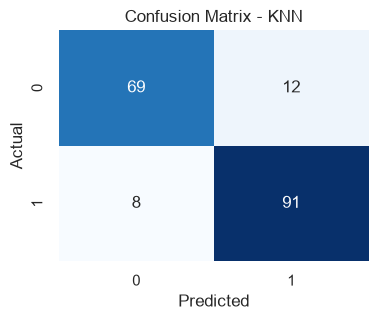

In [18]:
knn_default, knn_metrics, knn_pred = evaluate_model(
    KNeighborsClassifier(),
    "KNN"
)

### 5.3 Logistic Regression


Logistic Regression
              precision    recall  f1-score   support

           0       0.87      0.84      0.86        81
           1       0.87      0.90      0.89        99

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180



,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,Logistic Regression,0.8722,0.8725,0.8990,0.8856,0.0076


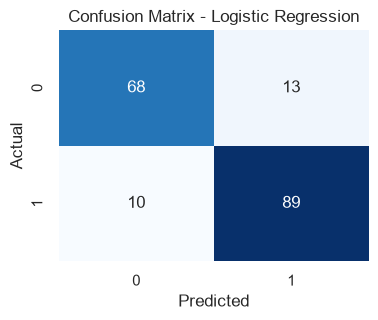

In [19]:
lr_default, lr_metrics, lr_pred = evaluate_model(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Logistic Regression"
)

### 5.4 Decision Tree


Decision Tree
              precision    recall  f1-score   support

           0       0.80      0.79      0.80        81
           1       0.83      0.84      0.83        99

    accuracy                           0.82       180
   macro avg       0.81      0.81      0.81       180
weighted avg       0.82      0.82      0.82       180



,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,Decision Tree,0.8167,0.8300,0.8384,0.8342,0.0061


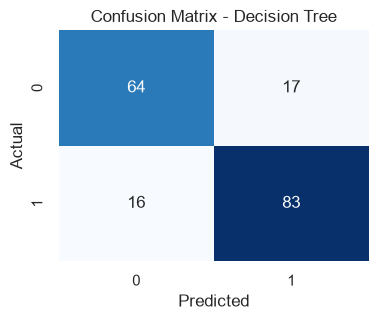

In [20]:
dt_default, dt_metrics, dt_pred = evaluate_model(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Decision Tree"
)

### 5.5 Random Forest


Random Forest
              precision    recall  f1-score   support

           0       0.88      0.83      0.85        81
           1       0.87      0.91      0.89        99

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180



,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,Random Forest,0.8722,0.8654,0.9091,0.8867,0.1892


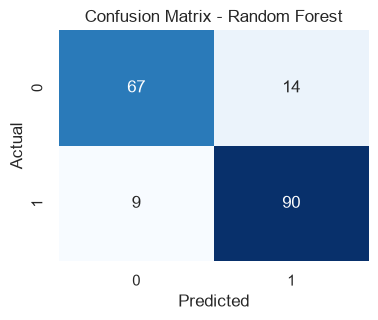

In [21]:
rf_default, rf_metrics, rf_pred = evaluate_model(
    RandomForestClassifier(random_state=RANDOM_STATE),
    "Random Forest"
)

### 5.6 Comparison table and bar chart of all four models

,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,KNN,0.8889,0.8835,0.9192,0.9010,0.0052
1,Logistic Regression,0.8722,0.8725,0.8990,0.8856,0.0076
2,Decision Tree,0.8167,0.8300,0.8384,0.8342,0.0061
3,Random Forest,0.8722,0.8654,0.9091,0.8867,0.1892


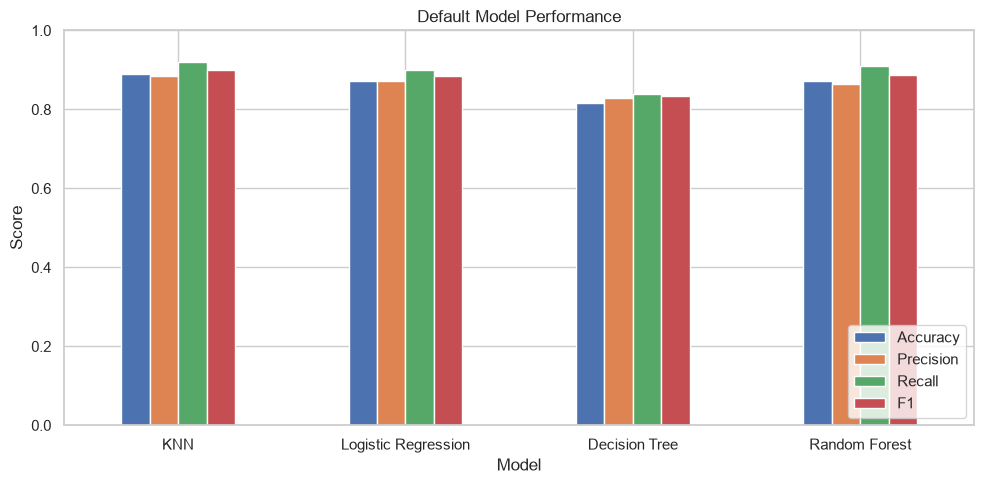

In [22]:
default_results = pd.DataFrame([
    knn_metrics, lr_metrics, dt_metrics, rf_metrics
])

display(default_results.round(4))

default_results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1)
)
plt.title("Default Model Performance")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Answer:** Among the default models, **KNN achieved the highest test accuracy of 88.89%**. In a medical diagnosis problem, accuracy should not be considered alone. **Recall is especially important** because a false negative means a patient with heart disease is incorrectly predicted as healthy. Therefore, the model should aim for high recall while also considering precision, F1-score, and the clinical cost of false positives and false negatives.

> ✍️ **Your answer:**
>
> _Double-click this cell and write your answer here._

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.

![kfold](attachment:kfold.png)

**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grids = {
    "KNN": {
        "n_neighbors": [3, 5, 7, 9, 11, 15],
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan"]
    },
    "Logistic Regression": {
        "C": [0.01, 0.1, 1, 10, 100],
        "penalty": ["l2"],
        "solver": ["lbfgs", "liblinear"]
    },
    "Decision Tree": {
        "max_depth": [None, 3, 5, 7, 10],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "criterion": ["gini", "entropy"]
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 5, 10, 15],
        "min_samples_split": [2, 5],
        "max_features": ["sqrt", "log2"]
    }
}

print("Cross-validation strategy:", cv)
print("\nParameter grids defined for:", list(param_grids.keys()))

Cross-validation strategy: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

Parameter grids defined for: ['KNN', 'Logistic Regression', 'Decision Tree', 'Random Forest']


### 6.2 Tune KNN


Tuned KNN
              precision    recall  f1-score   support

           0       0.90      0.86      0.88        81
           1       0.89      0.92      0.91        99

    accuracy                           0.89       180
   macro avg       0.89      0.89      0.89       180
weighted avg       0.89      0.89      0.89       180



,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,Tuned KNN,0.8944,0.8922,0.9192,0.9055,0.0027


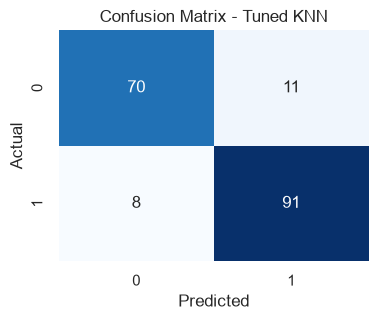

Best parameters: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
Best mean CV F1: 0.8932


In [24]:
knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grids["KNN"],
    cv=cv, scoring="f1", n_jobs=-1
)
knn_grid.fit(X_train_scaled, y_train)

knn_tuned, knn_tuned_metrics, knn_tuned_pred = evaluate_model(
    knn_grid.best_estimator_, "Tuned KNN"
)
knn_tuned_metrics["Best CV Score"] = knn_grid.best_score_
print("Best parameters:", knn_grid.best_params_)
print("Best mean CV F1:", round(knn_grid.best_score_, 4))

### 6.3 Tune Logistic Regression


Tuned Logistic Regression
              precision    recall  f1-score   support

           0       0.88      0.84      0.86        81
           1       0.87      0.91      0.89        99

    accuracy                           0.88       180
   macro avg       0.88      0.87      0.88       180
weighted avg       0.88      0.88      0.88       180



c:\Users\HP\image_proc_lab\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\HP\image_proc_lab\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,Tuned Logistic Regression,0.8778,0.8738,0.9091,0.8911,0.0110


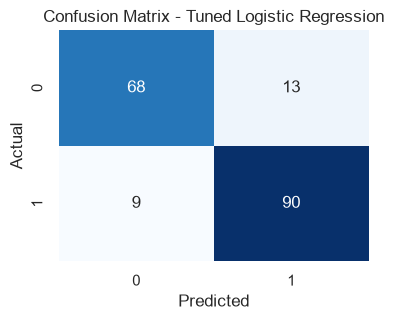

Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Best mean CV F1: 0.8812


In [25]:
lr_grid = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    param_grids["Logistic Regression"],
    cv=cv, scoring="f1", n_jobs=-1
)
lr_grid.fit(X_train_scaled, y_train)

lr_tuned, lr_tuned_metrics, lr_tuned_pred = evaluate_model(
    lr_grid.best_estimator_, "Tuned Logistic Regression"
)
lr_tuned_metrics["Best CV Score"] = lr_grid.best_score_
print("Best parameters:", lr_grid.best_params_)
print("Best mean CV F1:", round(lr_grid.best_score_, 4))

### 6.4 Tune Decision Tree


Tuned Decision Tree
              precision    recall  f1-score   support

           0       0.77      0.86      0.81        81
           1       0.88      0.79      0.83        99

    accuracy                           0.82       180
   macro avg       0.82      0.83      0.82       180
weighted avg       0.83      0.82      0.82       180



,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,Tuned Decision Tree,0.8222,0.8764,0.7879,0.8298,0.0031


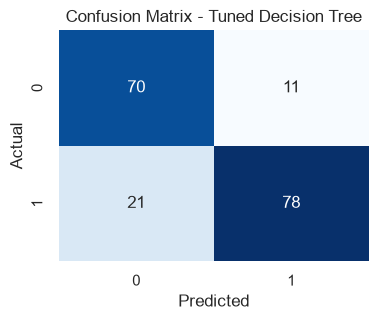

Best parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best mean CV F1: 0.8492


In [26]:
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grids["Decision Tree"],
    cv=cv, scoring="f1", n_jobs=-1
)
dt_grid.fit(X_train_scaled, y_train)

dt_tuned, dt_tuned_metrics, dt_tuned_pred = evaluate_model(
    dt_grid.best_estimator_, "Tuned Decision Tree"
)
dt_tuned_metrics["Best CV Score"] = dt_grid.best_score_
print("Best parameters:", dt_grid.best_params_)
print("Best mean CV F1:", round(dt_grid.best_score_, 4))

### 6.5 Tune Random Forest


Tuned Random Forest
              precision    recall  f1-score   support

           0       0.89      0.80      0.84        81
           1       0.85      0.92      0.88        99

    accuracy                           0.87       180
   macro avg       0.87      0.86      0.86       180
weighted avg       0.87      0.87      0.87       180



,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,Tuned Random Forest,0.8667,0.8505,0.9192,0.8835,0.1409


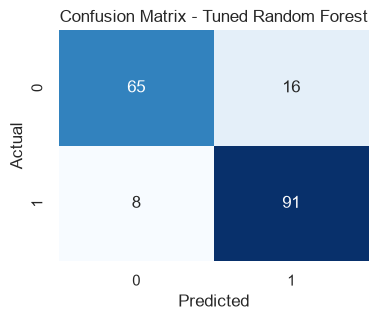

Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 100}
Best mean CV F1: 0.8897


In [27]:
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_grids["Random Forest"],
    cv=cv, scoring="f1", n_jobs=-1
)
rf_grid.fit(X_train_scaled, y_train)

rf_tuned, rf_tuned_metrics, rf_tuned_pred = evaluate_model(
    rf_grid.best_estimator_, "Tuned Random Forest"
)
rf_tuned_metrics["Best CV Score"] = rf_grid.best_score_
print("Best parameters:", rf_grid.best_params_)
print("Best mean CV F1:", round(rf_grid.best_score_, 4))

### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

In [28]:
tuned_results = pd.DataFrame([
    knn_tuned_metrics, lr_tuned_metrics, dt_tuned_metrics, rf_tuned_metrics
])

display(tuned_results.round(4))

print("Best tuned model by test F1:")
display(tuned_results.loc[tuned_results["F1"].idxmax()].to_frame().T.round(4))

,Model,Accuracy,Precision,Recall,F1,Training Time (s),Best CV Score
0,Tuned KNN,0.8944,0.8922,0.9192,0.9055,0.0027,0.8932
1,Tuned Logistic Regression,0.8778,0.8738,0.9091,0.8911,0.0110,0.8812
2,Tuned Decision Tree,0.8222,0.8764,0.7879,0.8298,0.0031,0.8492
3,Tuned Random Forest,0.8667,0.8505,0.9192,0.8835,0.1409,0.8897


Best tuned model by test F1:


,Model,Accuracy,Precision,Recall,F1,Training Time (s),Best CV Score
0,Tuned KNN,0.8944,0.8922,0.9192,0.9055,0.0027,0.8932


**Answer:** Hyperparameter tuning did **not** improve every model. Compared with the default models, tuned KNN, Logistic Regression, and Decision Tree showed small changes, while Random Forest's test accuracy decreased slightly. The largest improvement in F1-score was observed for **Logistic Regression**, increasing from about **0.8856 to 0.8911**. Tuning can help by selecting model complexity and regularisation settings that generalise better, but it can also produce little or no improvement when the default settings are already suitable.

> ✍️ **Your answer:**
>
> _Double-click this cell and write your answer here._

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.

![pca](attachment:pca.png)

**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

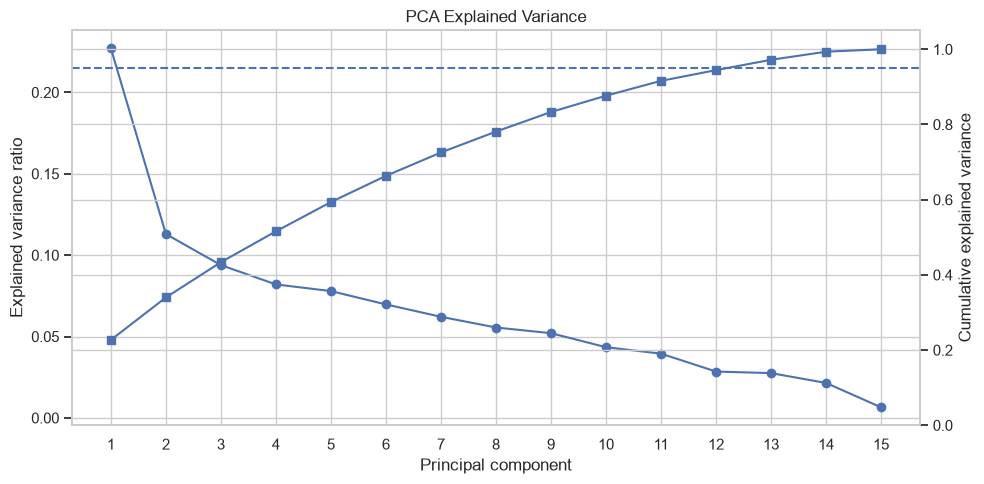

,Component,Explained Variance Ratio,Cumulative Variance
0,1,0.2270,0.2270
1,2,0.1129,0.3399
2,3,0.0939,0.4338
3,4,0.0820,0.5158
4,5,0.0779,0.5937
5,6,0.0697,0.6634
6,7,0.0621,0.7255
7,8,0.0555,0.7811
8,9,0.0521,0.8331
9,10,0.0434,0.8766


In [29]:
pca_full = PCA()
X_train_pca_full = pca_full.fit_transform(X_train_scaled)
X_test_pca_full = pca_full.transform(X_test_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

fig, ax1 = plt.subplots(figsize=(10, 5))
components = np.arange(1, len(explained_variance) + 1)

ax1.plot(components, explained_variance, marker="o", label="Individual explained variance")
ax1.set_xlabel("Principal component")
ax1.set_ylabel("Explained variance ratio")
ax1.set_xticks(components)

ax2 = ax1.twinx()
ax2.plot(components, cumulative_variance, marker="s", label="Cumulative explained variance")
ax2.axhline(0.95, linestyle="--", label="95% variance")
ax2.set_ylabel("Cumulative explained variance")
ax2.set_ylim(0, 1.05)

plt.title("PCA Explained Variance")
fig.tight_layout()
plt.show()

display(pd.DataFrame({
    "Component": components,
    "Explained Variance Ratio": explained_variance,
    "Cumulative Variance": cumulative_variance
}).round(4))

### 7.2 Determine the number of components for 95% variance

In [30]:
pca_95 = PCA(n_components=0.95)
X_train_pca = pca_95.fit_transform(X_train_scaled)
X_test_pca = pca_95.transform(X_test_scaled)

n_components_95 = pca_95.n_components_
original_features = X_train_scaled.shape[1]
reduction_percentage = (1 - n_components_95 / original_features) * 100

print("Components required for 95% variance:", n_components_95)
print("Original number of features:", original_features)
print("Reduced number of features:", n_components_95)
print("Feature reduction:", round(reduction_percentage, 2), "%")

Components required for 95% variance: 13
Original number of features: 15
Reduced number of features: 13
Feature reduction: 13.33 %


### 7.3 Transform the training and testing sets

In [31]:
print("X_train before PCA:", X_train_scaled.shape)
print("X_test before PCA :", X_test_scaled.shape)
print("X_train after PCA :", X_train_pca.shape)
print("X_test after PCA  :", X_test_pca.shape)

print("Explained variance retained:", round(pca_95.explained_variance_ratio_.sum(), 4))

X_train before PCA: (719, 15)
X_test before PCA : (180, 15)
X_train after PCA : (719, 13)
X_test after PCA  : (180, 13)
Explained variance retained: 0.972


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

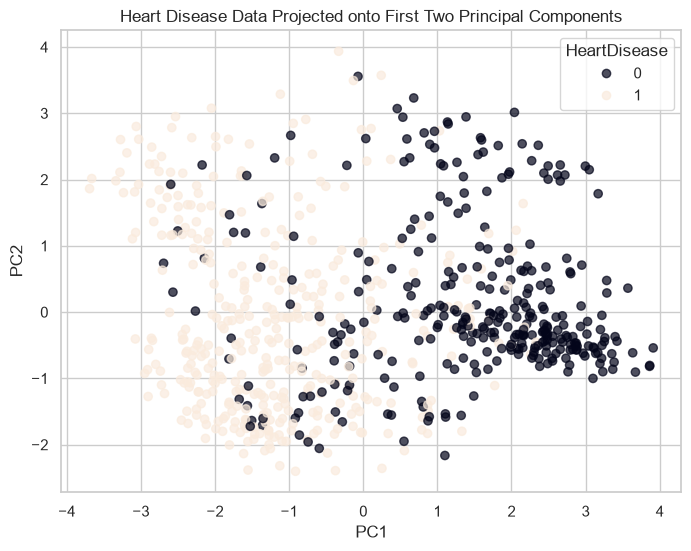

In [32]:
if original_features >= 2:
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
        X_train_pca[:, 0],
        X_train_pca[:, 1],
        c=y_train.to_numpy(),
        alpha=0.7
    )
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("Heart Disease Data Projected onto First Two Principal Components")
    plt.legend(*scatter.legend_elements(), title="HeartDisease")
    plt.show()

**Answer:** **13 principal components** are needed to retain at least **95% of the variance**. The original encoded dataset has 15 predictor features, so PCA reduces the dimensionality from 15 to 13 features. The feature reduction is approximately **13.33%**.

> ✍️ **Your answer:**
>
> _Double-click this cell and write your answer here._

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA


KNN
              precision    recall  f1-score   support

           0       0.91      0.89      0.90        81
           1       0.91      0.93      0.92        99

    accuracy                           0.91       180
   macro avg       0.91      0.91      0.91       180
weighted avg       0.91      0.91      0.91       180



,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,KNN,0.9111,0.9109,0.9293,0.9200,0.0015


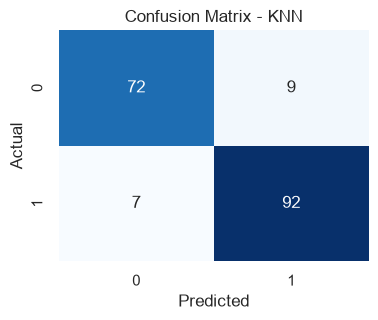

Best parameters: {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}
Best mean CV F1: 0.8884


In [33]:
pca_knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grids["KNN"],
    cv=cv, scoring="f1", n_jobs=-1
)
pca_knn_grid.fit(X_train_pca, y_train)

pca_knn, pca_knn_metrics, pca_knn_pred = evaluate_model(
    pca_knn_grid.best_estimator_,
    "KNN",
    X_train_data=X_train_pca,
    X_test_data=X_test_pca
)
pca_knn_metrics["Best CV Score"] = pca_knn_grid.best_score_

print("Best parameters:", pca_knn_grid.best_params_)
print("Best mean CV F1:", round(pca_knn_grid.best_score_, 4))

### 8.2 Logistic Regression after PCA


Logistic Regression
              precision    recall  f1-score   support

           0       0.87      0.85      0.86        81
           1       0.88      0.90      0.89        99

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180



c:\Users\HP\image_proc_lab\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\HP\image_proc_lab\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,Logistic Regression,0.8778,0.8812,0.8990,0.8900,0.0019


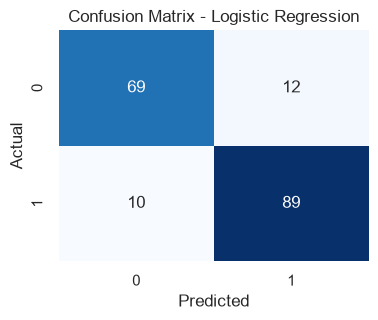

Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Best mean CV F1: 0.8812


In [34]:
pca_lr_grid = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    param_grids["Logistic Regression"],
    cv=cv, scoring="f1", n_jobs=-1
)
pca_lr_grid.fit(X_train_pca, y_train)

pca_lr, pca_lr_metrics, pca_lr_pred = evaluate_model(
    pca_lr_grid.best_estimator_,
    "Logistic Regression",
    X_train_data=X_train_pca,
    X_test_data=X_test_pca
)
pca_lr_metrics["Best CV Score"] = pca_lr_grid.best_score_

print("Best parameters:", pca_lr_grid.best_params_)
print("Best mean CV F1:", round(pca_lr_grid.best_score_, 4))

### 8.3 Decision Tree after PCA


Decision Tree
              precision    recall  f1-score   support

           0       0.86      0.85      0.86        81
           1       0.88      0.89      0.88        99

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180



,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,Decision Tree,0.8722,0.8800,0.8889,0.8844,0.0065


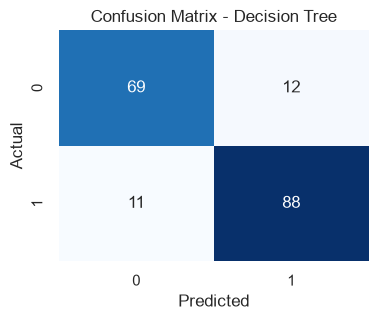

Best parameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best mean CV F1: 0.8523


In [35]:
pca_dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grids["Decision Tree"],
    cv=cv, scoring="f1", n_jobs=-1
)
pca_dt_grid.fit(X_train_pca, y_train)

pca_dt, pca_dt_metrics, pca_dt_pred = evaluate_model(
    pca_dt_grid.best_estimator_,
    "Decision Tree",
    X_train_data=X_train_pca,
    X_test_data=X_test_pca
)
pca_dt_metrics["Best CV Score"] = pca_dt_grid.best_score_

print("Best parameters:", pca_dt_grid.best_params_)
print("Best mean CV F1:", round(pca_dt_grid.best_score_, 4))

### 8.4 Random Forest after PCA


Random Forest
              precision    recall  f1-score   support

           0       0.91      0.85      0.88        81
           1       0.88      0.93      0.91        99

    accuracy                           0.89       180
   macro avg       0.90      0.89      0.89       180
weighted avg       0.90      0.89      0.89       180



,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,Random Forest,0.8944,0.8846,0.9293,0.9064,0.1575


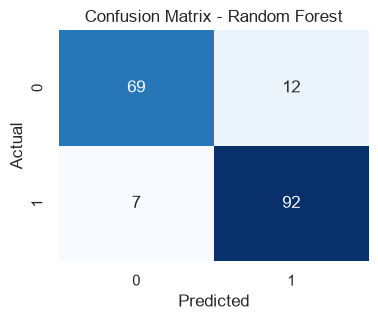

Best parameters: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}
Best mean CV F1: 0.8838


In [36]:
pca_rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_grids["Random Forest"],
    cv=cv, scoring="f1", n_jobs=-1
)
pca_rf_grid.fit(X_train_pca, y_train)

pca_rf, pca_rf_metrics, pca_rf_pred = evaluate_model(
    pca_rf_grid.best_estimator_,
    "Random Forest",
    X_train_data=X_train_pca,
    X_test_data=X_test_pca
)
pca_rf_metrics["Best CV Score"] = pca_rf_grid.best_score_

print("Best parameters:", pca_rf_grid.best_params_)
print("Best mean CV F1:", round(pca_rf_grid.best_score_, 4))

### 8.5 Comparison table of all four models after PCA

,Model,Accuracy,Precision,Recall,F1,Training Time (s),Best CV Score
0,KNN,0.9111,0.9109,0.9293,0.9200,0.0015,0.8884
1,Logistic Regression,0.8778,0.8812,0.8990,0.8900,0.0019,0.8812
2,Decision Tree,0.8722,0.8800,0.8889,0.8844,0.0065,0.8523
3,Random Forest,0.8944,0.8846,0.9293,0.9064,0.1575,0.8838


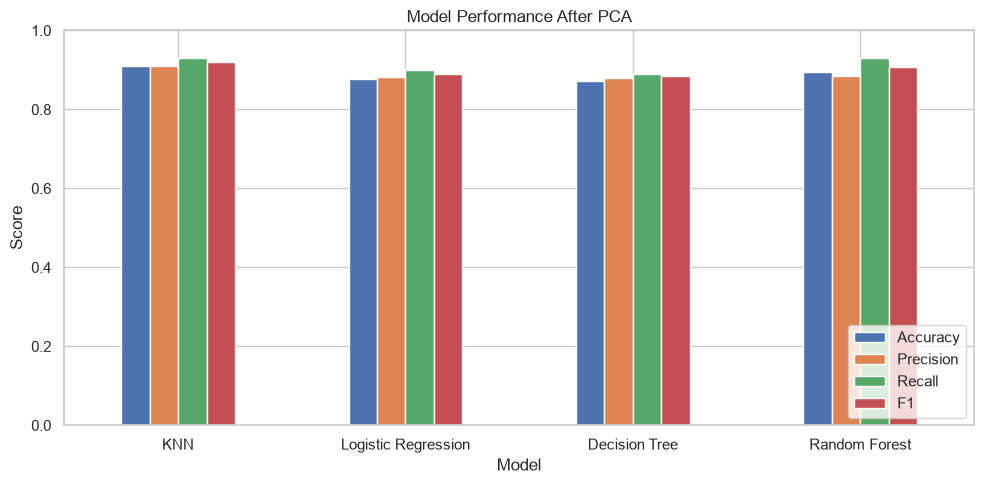

In [37]:
pca_results = pd.DataFrame([
    pca_knn_metrics, pca_lr_metrics, pca_dt_metrics, pca_rf_metrics
])

display(pca_results.round(4))

pca_results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1)
)
plt.title("Model Performance After PCA")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Answer:** After PCA, **KNN performed best**, with approximately **91.11% accuracy** and **0.9200 F1-score**. It was also the best-performing model before PCA based on the tuned test results. PCA therefore improved the KNN result on this dataset while reducing the number of features.

> ✍️ **Your answer:**
>
> _Double-click this cell and write your answer here._

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

In [38]:
before = tuned_results.copy()
before["Model"] = before["Model"].str.replace("Tuned ", "", regex=False)
before = before.set_index("Model")
after = pca_results.set_index("Model")

comparison = pd.DataFrame({
    "Model": before.index,
    "Accuracy (Before PCA)": before["Accuracy"].values,
    "Accuracy (After PCA)": after.loc[before.index, "Accuracy"].values,
    "F1 (Before PCA)": before["F1"].values,
    "F1 (After PCA)": after.loc[before.index, "F1"].values,
    "Training Time Before (s)": before["Training Time (s)"].values,
    "Training Time After (s)": after.loc[before.index, "Training Time (s)"].values,
    "No. of Features": [original_features] * len(before)
})

display(comparison.round(4))

,Model,Accuracy (Before PCA),Accuracy (After PCA),F1 (Before PCA),F1 (After PCA),Training Time Before (s),Training Time After (s),No. of Features
0,KNN,0.8944,0.9111,0.9055,0.9200,0.0027,0.0015,15
1,Logistic Regression,0.8778,0.8778,0.8911,0.8900,0.0110,0.0019,15
2,Decision Tree,0.8222,0.8722,0.8298,0.8844,0.0031,0.0065,15
3,Random Forest,0.8667,0.8944,0.8835,0.9064,0.1409,0.1575,15


### 9.2 Visualise the before vs after PCA comparison

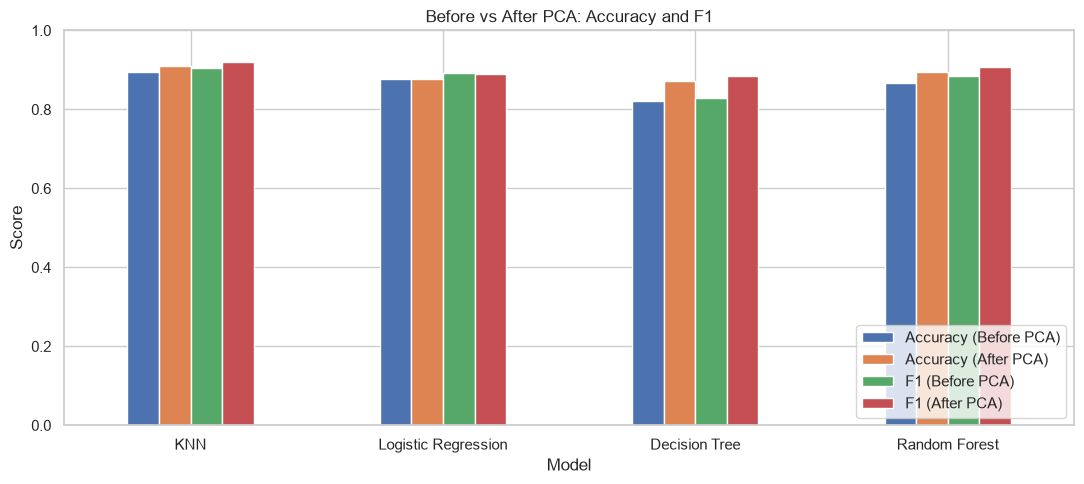

In [39]:
comparison_plot = comparison.set_index("Model")[
    ["Accuracy (Before PCA)", "Accuracy (After PCA)", "F1 (Before PCA)", "F1 (After PCA)"]
]

comparison_plot.plot(kind="bar", figsize=(11, 5), ylim=(0, 1))
plt.title("Before vs After PCA: Accuracy and F1")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

**Answer:** PCA improved the test accuracy of KNN, Decision Tree, and Random Forest, while Logistic Regression remained slightly lower than its pre-PCA result. KNN showed the strongest overall result after PCA, reaching about **91.11% accuracy** and **0.9200 F1-score**.

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

**Answer:** PCA reduced the feature space from **15 to 13 features**, a **13.33% reduction**. Fewer features can reduce the amount of computation and memory required by algorithms, especially when datasets contain many redundant or correlated variables. In this small dataset, the practical time saving is limited, and the PCA transformation plus cross-validation also adds overhead.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based models).

**Answer:** On this dataset, PCA generally **improved or maintained** performance for most models, although Logistic Regression declined slightly. PCA can remove redundant or noisy directions and create compact features containing most of the variance. However, the original dataset already has only 15 encoded predictors, so the dimensionality reduction is relatively small. Tree-based models can also behave differently because PCA creates linear combinations of the original features rather than preserving the original feature meanings.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

**Answer:** PCA can reduce dimensionality and computational cost, but the transformed components are less interpretable than the original clinical features and some predictive information may be lost. I would prefer PCA when the dataset has many correlated or redundant features, computational efficiency is important, or the original feature space is very high-dimensional. I would avoid using PCA when interpretability of individual features is critical or when the original number of features is already small.

> ✍️ **Your answer:**
>
> _Double-click this cell and write your answer here._

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

> ✍️ **Your answer:**
>
> _Double-click this cell and write your answer here._

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

> ✍️ **Your answer:**
>
> _Double-click this cell and write your answer here._

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

> ✍️ **Your answer:**
>
> _Double-click this cell and write your answer here._

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.